In [1]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from nltk import sent_tokenize
from nltk.corpus import abc, stopwords

import word2vec as w2v

In [2]:
# ABC Science news articles
corpus = abc.raw('science.txt')
print(corpus[:350])

Cystic fibrosis affects 30,000 children and young adults in the US alone
Inhaling the mists of salt water can reduce the pus and infection that fills the airways of cystic fibrosis sufferers, although side effects include a nasty coughing fit and a harsh taste. 
That's the conclusion of two studies published in this week's issue of The New Englan


In [3]:
sentences = sent_tokenize(corpus)
tokenized_sentences = [w2v.tokenize(sentence) for sentence in sentences]

train_sentences, val_sentences, _ = w2v.random_split(
    tokenized_sentences, (0.70, 0.85), seed=42
)
word_to_id, id_to_word, _ = w2v.build_vocab(train_sentences, min_count=5)

token_coverage, type_coverage = w2v.vocab_coverage(val_sentences, word_to_id)
print(f'Training vocabulary  {len(word_to_id):,} words')
print(f'Validation coverage  {token_coverage:.2%} of word occurrences')
print(f'                     {type_coverage:.2%} of distinct words')

Training vocabulary  5,359 words
Validation coverage  89.05% of word occurrences
                     48.72% of distinct words


In [4]:
WINDOW_SIZE = 2

train_pairs = w2v.generate_pairs(train_sentences, word_to_id, WINDOW_SIZE)
val_pairs = w2v.generate_pairs(val_sentences, word_to_id, WINDOW_SIZE)

print(f'Training pairs    {len(train_pairs):,}')
print(f'Validation pairs  {len(val_pairs):,}')

Training pairs    788,518
Validation pairs  161,286


In [5]:
BATCH_SIZE = 64

model = w2v.Word2Vec(word_to_id, id_to_word, embedding_dim=64, seed=42)
initial_train_loss = model.evaluate(train_pairs, batch_size=BATCH_SIZE)
initial_val_loss = model.evaluate(val_pairs, batch_size=BATCH_SIZE)

train_loss_history, val_loss_history = model.train(
    train_pairs,
    val_pairs,
    epochs=20,
    batch_size=BATCH_SIZE,
    learning_rate=0.7,
    restore_best_weights=True,
)

In [6]:
best_epoch = int(np.argmin(val_loss_history)) + 1
best_val_loss = val_loss_history[best_epoch - 1]

print(f'Validation loss  {best_val_loss:.4f} at epoch {best_epoch} → '
      f'{val_loss_history[-1]:.4f} at epoch {EPOCHS}')
print(f'Training loss    {train_loss_history[best_epoch - 1]:.4f} at epoch {best_epoch} → '
      f'{train_loss_history[-1]:.4f} at epoch {EPOCHS}')

Validation loss  6.2408 at epoch 10 → 6.2719 at epoch 20
Training loss    6.0346 at epoch 10 → 5.8406 at epoch 20


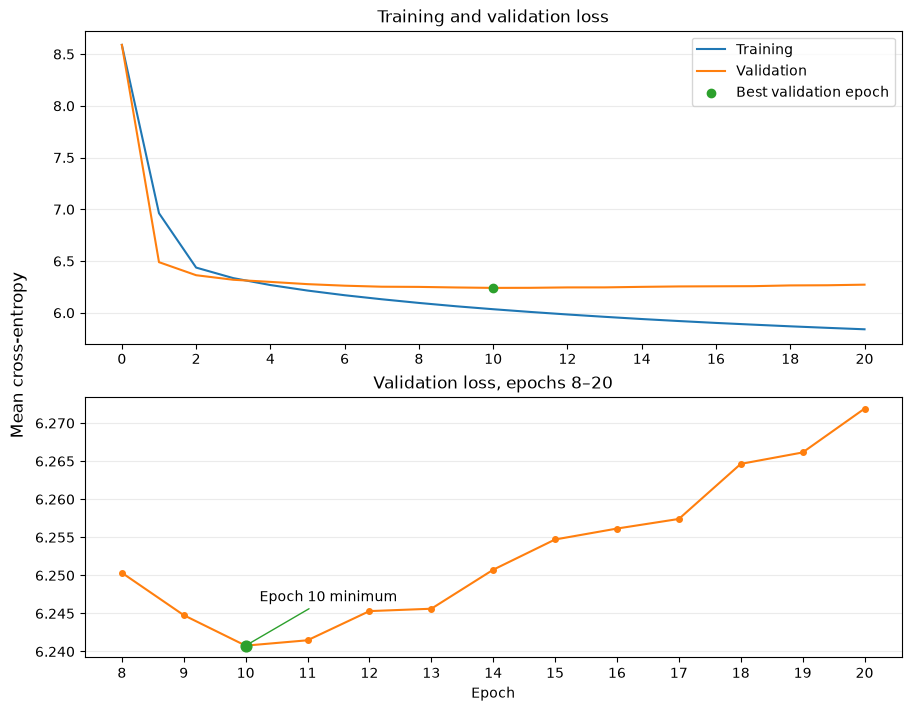

In [7]:
epochs = range(EPOCHS + 1)
training_losses = [initial_train_loss, *train_loss_history]
validation_losses = [initial_val_loss, *val_loss_history]
zoom_start = 8

fig, (full_ax, zoom_ax) = plt.subplots(
    2, 1, figsize=(9, 7), height_ratios=(1.2, 1), layout='constrained'
)
best_epoch_color = 'tab:green'
full_ax.plot(epochs, training_losses, color='tab:blue', label='Training')
full_ax.plot(epochs, validation_losses, color='tab:orange', label='Validation')
full_ax.scatter(
    best_epoch, best_val_loss, color=best_epoch_color, zorder=3, label='Best validation epoch'
)
full_ax.set(title='Training and validation loss', xticks=range(0, EPOCHS + 1, 2))
full_ax.legend()

zoom_ax.plot(
    epochs[zoom_start:], validation_losses[zoom_start:],
    color='tab:orange', marker='o', markersize=4,
)
zoom_ax.scatter(best_epoch, best_val_loss, color=best_epoch_color, s=60, zorder=3)
zoom_ax.annotate(
    f'Epoch {best_epoch} minimum',
    (best_epoch, best_val_loss),
    xytext=(10, 32),
    textcoords='offset points',
    arrowprops={'arrowstyle': '-', 'color': best_epoch_color},
)
zoom_ax.set(
    title=f'Validation loss, epochs {zoom_start}–{EPOCHS}',
    xlabel='Epoch',
    xticks=epochs[zoom_start:],
)

for ax in (full_ax, zoom_ax):
    ax.grid(axis='y', alpha=0.25)

fig.supylabel('Mean cross-entropy')
plt.show()

In [8]:
def format_contexts(contexts):
    return ', '.join(f'`{word}` ({probability:.1%})' for word, probability in contexts)


query_words = ('planet', 'climate', 'cancer', 'telescope')
excluded_contexts = set(stopwords.words('english')) | {'st', 'nd', 'rd', 'th'}
rows = [
    '| Center | Closest cosine neighbors | Top context guesses | Top content-word guesses |',
    '|---|---|---|---|',
]

for word in query_words:
    neighbors = ', '.join(
        f'`{neighbor}` ({similarity:.2f})'
        for neighbor, similarity in model.most_similar(word, k=5)
    )
    ranked_contexts = model.predict_context(word, k=len(word_to_id))
    top_contexts = format_contexts(ranked_contexts[:3])
    content_contexts = [
        (context, probability) for context, probability in ranked_contexts
        if context not in excluded_contexts
    ][:3]
    top_content = format_contexts(content_contexts)
    rows.append(f'| `{word}` | {neighbors} | {top_contexts} | {top_content} |')

display(Markdown('\n'.join(rows)))

| Center | Closest cosine neighbors | Top context guesses | Top content-word guesses |
|---|---|---|---|
| `planet` | `giant` (0.62), `star` (0.61), `ring` (0.60), `object` (0.58), `spring` (0.58) | `the` (8.9%), `a` (6.4%), `of` (3.9%) | `says` (1.4%), `earth` (0.9%), `first` (0.6%) |
| `climate` | `warming` (0.60), `global` (0.53), `significant` (0.52), `evolutionary` (0.52), `induced` (0.51) | `change` (20.0%), `of` (4.8%), `on` (4.0%) | `change` (20.0%), `global` (2.3%), `says` (1.1%) |
| `cancer` | `lung` (0.61), `attack` (0.58), `heart` (0.58), `infectious` (0.57), `alzheimer's` (0.53) | `breast` (6.8%), `cells` (5.1%), `and` (4.3%) | `breast` (6.8%), `cells` (5.1%), `disease` (1.1%) |
| `telescope` | `mission` (0.58), `service` (0.57), `measurement` (0.54), `fabric` (0.53), `fleet` (0.53) | `the` (8.0%), `space` (7.0%), `a` (5.8%) | `space` (7.0%), `hubble` (3.3%), `new` (1.6%) |

In [9]:
demo_sentence = 'Stem cells are master cells that have the potential to develop into any organ of the body.'
demo_tokens = w2v.tokenize(demo_sentence)

rows = [
    '| Current word | Top three context guesses | Actual next word | Rank |',
    '|---|---|---|---:|',
]
top_three_hits = 0
ranked_steps = 0

for current_word, next_word in zip(demo_tokens, demo_tokens[1:]):
    if current_word not in word_to_id or next_word not in word_to_id:
        rows.append(f'| `{current_word}` | Outside vocabulary | `{next_word}` | — |')
        continue

    ranked_contexts = model.predict_context(current_word, k=len(word_to_id))
    guesses = format_contexts(ranked_contexts[:3])
    context_words = [word for word, _ in ranked_contexts]
    rank = context_words.index(next_word) + 1
    ranked_steps += 1
    actual = f'`{next_word}`'
    rank_text = f'{rank:,}'
    if rank <= 3:
        top_three_hits += 1
        actual = f'**{actual}**'
        rank_text = f'**{rank_text}**'
    rows.append(f'| `{current_word}` | {guesses} | {actual} | {rank_text} |')

summary = f'**{top_three_hits} of {ranked_steps} ranked steps** put the actual next word in the top three.'
display(Markdown(f'> {demo_sentence}\n\n{summary}\n\n' + '\n'.join(rows)))

> Stem cells are master cells that have the potential to develop into any organ of the body.

**6 of 16 ranked steps** put the actual next word in the top three.

| Current word | Top three context guesses | Actual next word | Rank |
|---|---|---|---:|
| `stem` | `cells` (17.9%), `cell` (9.2%), `embryonic` (6.8%) | **`cells`** | **1** |
| `cells` | `stem` (7.5%), `the` (6.0%), `that` (4.3%) | `are` | 9 |
| `are` | `to` (5.7%), `the` (5.6%), `they` (3.5%) | `master` | 1,411 |
| `master` | `cells` (26.9%), `the` (9.2%), `to` (8.8%) | **`cells`** | **1** |
| `cells` | `stem` (7.5%), `the` (6.0%), `that` (4.3%) | **`that`** | **3** |
| `that` | `the` (4.1%), `is` (2.9%), `found` (2.0%) | `have` | 12 |
| `have` | `to` (6.6%), `the` (4.1%), `been` (3.8%) | **`the`** | **2** |
| `the` | `of` (7.6%), `in` (4.3%), `to` (3.0%) | `potential` | 271 |
| `potential` | `to` (13.3%), `the` (8.6%), `for` (8.3%) | **`to`** | **1** |
| `to` | `the` (4.0%), `be` (1.8%), `have` (1.5%) | `develop` | 31 |
| `develop` | `to` (15.2%), `a` (4.2%), `and` (2.6%) | `into` | 8 |
| `into` | `the` (6.1%), `a` (4.0%), `it` (1.9%) | `any` | 73 |
| `any` | `of` (6.1%), `to` (3.6%), `and` (2.9%) | `organ` | 1,888 |
| `organ` | `the` (7.3%), `and` (5.9%), `to` (5.5%) | `of` | 8 |
| `of` | `the` (13.0%), `a` (4.1%), `university` (2.3%) | **`the`** | **1** |
| `the` | `of` (7.6%), `in` (4.3%), `to` (3.0%) | `body` | 145 |

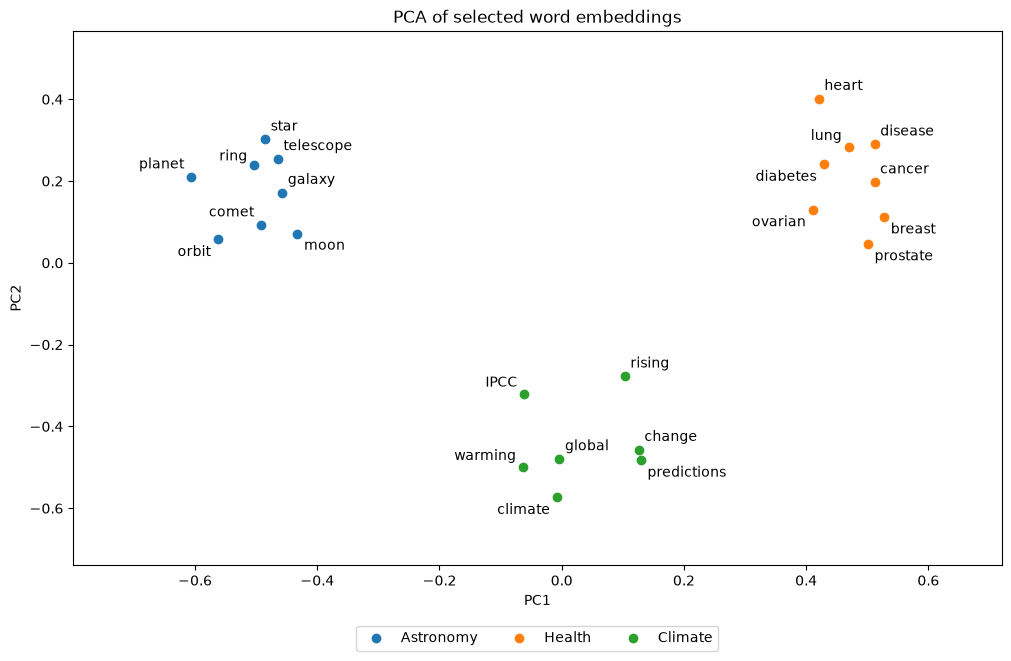

In [10]:
word_groups = {
    'Astronomy': ('planet', 'star', 'orbit', 'telescope', 'galaxy', 'moon', 'comet', 'ring'),
    'Health': ('cancer', 'lung', 'breast', 'disease', 'heart', 'ovarian', 'prostate', 'diabetes'),
    'Climate': ('climate', 'warming', 'global', 'change', 'ipcc', 'rising', 'predictions'),
}

words = [word for group in word_groups.values() for word in group]
vectors = model.input_embeddings[[word_to_id[word] for word in words]]
coordinates = dict(zip(words, w2v.pca_2d(vectors, normalize=True)))
label_offsets = {
    'planet': (-5, 4),
    'orbit': (-5, -4),
    'ring': (-5, 1),
    'comet': (-5, 4),
    'moon': (5, -4),
    'lung': (-5, 3),
    'diabetes': (-5, -4),
    'ovarian': (-5, -4),
    'breast': (5, -4),
    'prostate': (5, -4),
    'warming': (-5, 3),
    'climate': (-5, -4),
    'ipcc': (-5, 3),
    'predictions': (5, -4),
}

fig, ax = plt.subplots(figsize=(10, 6.5), layout='constrained')
for label, group in word_groups.items():
    points = np.array([coordinates[word] for word in group])
    ax.scatter(points[:, 0], points[:, 1], label=label)
    for word, point in zip(group, points):
        dx, dy = label_offsets.get(word, (4, 4))
        display_word = 'IPCC' if word == 'ipcc' else word
        ax.annotate(
            display_word, point, xytext=(dx, dy), textcoords='offset points',
            ha='right' if dx < 0 else 'left', va='top' if dy < 0 else 'bottom',
        )

ax.set(xlabel='PC1', ylabel='PC2', title='PCA of selected word embeddings')
ax.margins(0.17)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.10), ncols=len(word_groups))
plt.show()